# Step 2 (version 2): intraday price data of the version 2 pairs

**Goal.** From the 1-minute dataset (`data/processed/intraday_1m_all.parquet`) build, for each of the **15 pairs of version 2** (`selected_pairs_2.csv`, see [01_pairs.ipynb](01_pairs.ipynb)), a **clean file** with the two stocks aligned on the same minutes. It will be the starting point for the signal (Step 4) and for the simulation (Step 6).

**Version 1 and version 2.** Version 1 is the first 10 pairs ([intraday_pulizia.ipynb](../Old%20files/src/02_dati_intraday/intraday_pulizia.ipynb), now in `Old files/`, in Italian; files in `data/processed/pairs_intraday/`). This notebook does **exactly the same work** on the version 2 pairs and writes to a **separate** folder, `data/processed/pairs_intraday_v2/`, so the two versions do not mix and do not overwrite each other. The cleaning method is the same as version 1: only the list of pairs, and so the stocks, changes.

**What the notebook does**

| Part | What it does | Why |
|---|---|---|
| 1-2 | Parameters and loading of the 30 stocks | we work only on the stocks we need |
| 3 | Check of the unadjusted prices | splits must not look like crashes |
| 4 | Quality of the raw data | bars per day, missing days, half days |
| 5 | Cleaning function: alignment and filling | the core of the step |
| 6 | Cleaning of the 15 pairs and checks | how many bars filled or discarded |
| 7 | 5-, 15- and 60-minute bars | to choose the frequency later (decision 1 of the plan) |
| 8 | One chart per pair | visual check |
| 9 | Results (text for the report) | numbers generated from the data |
| 10 | Saving and summary | files for the next phases |

**Rules of the plan applied** (Step 2 of [Programma.md](../Old%20files/docs/Programma.md), the group's log, in Italian):
- a single time zone, New York time (the data are already converted by `src/data.py`), and only the **regular session, 09:30-15:59** (390 1-minute bars);
- the two stocks of each pair are **aligned on the same time**;
- missing bars are filled **only by carrying forward the previous price, never with future prices** (Lecture 5): using future prices would be lookahead bias;
- prices should be **adjusted for splits and dividends**: the intraday ones are not, so the absence of splits is checked (part 3);
- checks: number of bars per day, half days, one chart per pair.

**What is NOT touched:** the list of version 2 pairs, the data of the daily selection period and the thresholds of Step 1. No pair is discarded in this step.

## 1. Parameters

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # project folder: makes src importable

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

from src.config import PAIRS_DIR, PROCESSED, SELECTED

INTRADAY = PROCESSED / "intraday_1m_all.parquet"    # 1-minute bars, New York times
DAILY    = PROCESSED / "daily_all.parquet"
OUT_DIR  = PAIRS_DIR                                # clean files, one per pair and per frequency

SESSION_OPEN_MIN = 9 * 60 + 30      # 09:30 open, in minutes from midnight
N_MINUTES = 390                     # 1-minute bars in the regular session: 09:30-15:59
FREQUENCIES = [1, 5, 15, 60]        # minutes per bar
# [ECO] The plan says to keep the minute and build the others with resample: the right frequency is chosen
#   by comparing the results (decision 1), so all of them are saved.

SPLIT_GAP = 0.15                    # gap between yesterday's close and today's open beyond 15%: suspected split
CLOSE_VS_DAILY_TOL = 0.05           # intraday close against the daily PX_LAST beyond 5%: suspected unadjusted price
JUMP_1MIN = 0.05                    # 1-minute return beyond 5%: to be checked
HALF_DAY_LAST_BAR = "15:30"         # if the median last bar of the stocks is earlier, it is a half day
# [OURS] Alarm thresholds for the checks: they do not discard data on their own, they bring out the cases to look at by hand.

## 2. Loading the 30 stocks of the pairs

Only the stocks of the pairs are read (30 out of 503): the whole dataset has over 13 million rows. DuckDB reads the file without loading it all into memory. The time is New York time **without a time-zone indication** in the data (all minutes are already in New York time, so the comparison between days stays correct even with the daylight-saving change, which in the June-October period falls only in November).

In [2]:
pairs = pd.read_csv(SELECTED)
pairs["origin"] = "version 2"    # all chosen by the rule, none added by hand
tickers = sorted(set(pairs["A"]) | set(pairs["B"]))
in_list = ", ".join(repr(t) for t in tickers)

raw = duckdb.sql(f'''
    SELECT ticker, date, time, open, high, low, close, volume, n_events
    FROM '{INTRADAY.as_posix()}' WHERE ticker IN ({in_list})
''').df()
raw["ts"] = pd.to_datetime(raw["date"].astype(str) + " " + raw["time"].astype(str))
raw["date"] = pd.to_datetime(raw["date"])
raw = raw.drop(columns="time").sort_values(["ticker", "ts"]).reset_index(drop=True)

print(f"{len(tickers)} stocks, {len(raw):,} 1-minute bars, from {raw['date'].min().date()} to {raw['date'].max().date()}")
print("bars outside 09:30-15:59:", int(((raw['ts'].dt.hour * 60 + raw['ts'].dt.minute < SESSION_OPEN_MIN) | (raw['ts'].dt.hour * 60 + raw['ts'].dt.minute >= SESSION_OPEN_MIN + N_MINUTES)).sum()))

30 stocks, 979,861 1-minute bars, from 2026-06-16 to 2026-10-30
bars outside 09:30-15:59: 0


## 3. Check: intraday prices are not adjusted

Daily prices (`PX_LAST`) are adjusted for splits and dividends, intraday ones are **not**: a split (for example 2 shares for 1) shows up as a -50% gap from one evening to the next morning, and would make a spread look huge when it is not. Two checks:
1. **Gap between the close of a day and the open of the next day**, for each stock: beyond 15% it is suspicious.
2. **Last bar of the day against the daily `PX_LAST`** of the same day: if the two prices differ by more than 5%, one of the two is not comparable (typical of a split that happened later, which the daily data have already corrected on the history).

If a split appears, the prices before the split must be divided by its factor, and the correction must be stated.

In [3]:
sess = raw.groupby(["ticker", "date"]).agg(first_open=("open", "first"), last_close=("close", "last"), bars=("close", "size"),
                                           first_bar=("ts", "min"), last_bar=("ts", "max")).reset_index()
sess["gap"] = sess["first_open"] / sess.groupby("ticker")["last_close"].shift() - 1

daily = duckdb.sql(f"SELECT ticker, CAST(date AS TIMESTAMP) AS date, PX_LAST FROM '{DAILY.as_posix()}' WHERE ticker IN ({in_list}) AND date >= '{raw['date'].min().date()}'").df()
sess = sess.merge(daily, on=["ticker", "date"], how="left")
sess["close_vs_daily"] = sess["last_close"] / sess["PX_LAST"] - 1

suspect_gap = sess[sess["gap"].abs() > SPLIT_GAP]
suspect_px = sess[sess["close_vs_daily"].abs() > CLOSE_VS_DAILY_TOL]
print(f"overnight gaps beyond {SPLIT_GAP:.0%}: {len(suspect_gap)} cases | intraday close beyond {CLOSE_VS_DAILY_TOL:.0%} from the daily: {len(suspect_px)} cases")
display(sess.groupby("ticker")[["gap", "close_vs_daily"]].agg(lambda s: s.abs().max()).rename(columns={"gap": "gap_max", "close_vs_daily": "max_diff_from_daily"}).round(4))
suspect_gap[["ticker", "date", "first_open", "last_close", "gap", "PX_LAST"]].assign(gap=lambda d: d["gap"].round(4))

overnight gaps beyond 15%: 2 cases | intraday close beyond 5% from the daily: 0 cases


,gap_max,max_diff_from_daily
ticker,,
BAC UN Equity,0.0805,0.0061
C UN Equity,0.0263,0.0115
CL UN Equity,0.0515,0.0119
COP UN Equity,0.0431,0.0070
CRM UN Equity,0.1340,0.0040
CSX UW Equity,0.0425,0.0027
DHR UN Equity,0.1655,0.0045
ELV UN Equity,0.0821,0.0127
EOG UN Equity,0.0379,0.0147


,ticker,date,first_open,last_close,gap,PX_LAST
589,DHR UN Equity,2026-07-21,168.25,179.01,-0.1655,178.6933
1919,PYPL UW Equity,2026-07-15,54.87,55.52,0.1583,55.3832


**Reading.** An intraday close always within 5% of the daily rules out a split in the period (the table above reports the maximum difference per stock): after a split the two prices would differ by an integer factor. A large overnight gap is **not** necessarily a split: it can be real news. To tell them apart, one checks whether the (adjusted) daily data show the same move: if so, it is a real move and the intraday prices can be used as they are.

## 4. Quality of the raw data

Three things to know before cleaning:
- **Missing days.** A stock may have no data on some days (the check on the whole dataset had already flagged days in September).
- **Missing bars.** In the raw data there is a bar only in the minutes in which at least one trade took place: less traded stocks have many empty minutes. An empty minute is not wrong data: it means that the price did not change (no trade).
- **Half days.** On half-day sessions (for example on the eve of some holidays) the exchange closes early: the bars after the close do not exist and must not be "invented".

In [4]:
day_bars = sess.pivot(index="date", columns="ticker", values="bars")
print("trading days in the period (at least one stock):", len(day_bars))
missing = day_bars.isna().sum()
display(pd.DataFrame({"days_present": day_bars.notna().sum(), "days_missing": missing,
                      "bars_per_day_median": day_bars.median().round(0), "bars_per_day_min": day_bars.min()}))
for tk in missing[missing > 0].index:
    print(tk, "missing on the days:", ", ".join(d.strftime("%Y-%m-%d") for d in day_bars.index[day_bars[tk].isna()]))

trading days in the period (at least one stock): 96


,days_present,days_missing,bars_per_day_median,bars_per_day_min
ticker,,,,
BAC UN Equity,96,0,389.0,376.0
C UN Equity,96,0,372.0,293.0
CL UN Equity,96,0,339.0,261.0
COP UN Equity,91,5,386.0,324.0
CRM UN Equity,96,0,378.0,318.0
CSX UW Equity,91,5,383.0,351.0
DHR UN Equity,96,0,289.0,208.0
ELV UN Equity,96,0,245.0,160.0
EOG UN Equity,96,0,306.0,222.0


COP UN Equity missing on the days: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
CSX UW Equity missing on the days: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
GS UN Equity missing on the days: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
LOW UN Equity missing on the days: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
SYK UN Equity missing on the days: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17
TMO UN Equity missing on the days: 2026-09-11, 2026-09-14, 2026-09-15, 2026-09-16, 2026-09-17


In [5]:
# half days: median last bar of the stocks before 15:30
last = sess.assign(last_min=sess["last_bar"].dt.hour * 60 + sess["last_bar"].dt.minute).groupby("date")["last_min"].median()
limit = int(HALF_DAY_LAST_BAR[:2]) * 60 + int(HALF_DAY_LAST_BAR[3:])
half_days = last[last < limit]
print("half days:", [d.strftime("%Y-%m-%d") for d in half_days.index] or "none")
print("days with fewer bars (median across the stocks):")
day_bars.median(axis=1).sort_values().head(5).to_frame("median_bars")

half days: none
days with fewer bars (median across the stocks):


,median_bars
date,
2026-07-10,330.5
2026-07-09,337.5
2026-08-26,339.5
2026-10-06,341.5
2026-10-09,342.0


## 5. How a pair is cleaned

For each pair (stock A and stock B) four steps are done, each with its reason.

1. **Days in common.** Only the days on which **both** stocks have data are kept. If one of the two is missing, the other has nothing to form the spread with, and inventing a whole day would be wrong. The discarded days are counted and reported.
2. **Full 390-minute grid** (09:30-15:59) for each kept day: each stock is brought onto the same grid, so the two series are compared row by row.
3. **Forward filling, only within the same day.** A minute without trades takes the close price of the last previous bar **of the same day**: open, high, low and close equal to that price, volume 0. The price of the previous day is never copied onto the next day: between 16:00 and 9:30 the price may have changed (news, earnings), and a price copied across the night would be false. Forward filling never uses future information (no lookahead bias). Every filled bar has `filled = True`, so it is always possible to count and understand how much of the data is "real".
4. **Initial minutes without a price.** If a stock makes its first trade after 9:30, there is no price of the day for the earlier minutes: **they are not invented**. Those minutes are discarded for both stocks, up to the first minute in which both have a price. (The plan anyway foresees excluding the first 30 minutes from trading, because prices are unstable.)

**File format** (one file per pair, one stock per row, as in the table of exchanged files of the plan): `ts` (New York time), `ticker`, `open`, `high`, `low`, `close`, `volume`, `n_events`, `filled`.

In [6]:
grid_offsets = pd.to_timedelta(np.arange(N_MINUTES) + SESSION_OPEN_MIN, unit="min")    # 09:30 ... 15:59

def clean_pair(a, b):
    # Returns (clean data in long format, statistics) for the pair a, b.
    by_ticker = {tk: raw[raw["ticker"] == tk] for tk in (a, b)}
    days_a, days_b = set(by_ticker[a]["date"]), set(by_ticker[b]["date"])
    days = sorted(days_a & days_b)
    dropped_days = sorted((days_a | days_b) - set(days))

    grid = pd.DatetimeIndex([d + off for d in days for off in grid_offsets])
    day_of = grid.normalize()
    parts = {}
    for tk in (a, b):
        s = by_ticker[tk][by_ticker[tk]["date"].isin(days)].set_index("ts")[["open", "high", "low", "close", "volume", "n_events"]].reindex(grid)
        filled = s["close"].isna()
        close = s["close"].groupby(day_of).ffill()           # only within the same day
        out = pd.DataFrame({"ts": grid, "ticker": tk, "open": s["open"], "high": s["high"], "low": s["low"], "close": close,
                            "volume": s["volume"].fillna(0).astype("int64"), "n_events": s["n_events"].fillna(0).astype("int64"), "filled": filled.values})
        for col in ("open", "high", "low"):
            out[col] = out[col].where(~filled, out["close"])    # filled bar: open = high = low = close = last known price
        parts[tk] = out.reset_index(drop=True)

    both = parts[a]["close"].notna().values & parts[b]["close"].notna().values       # no invented price in the initial minutes
    long = pd.concat([parts[a][both], parts[b][both]]).sort_values(["ts", "ticker"]).reset_index(drop=True)

    stats = dict(pair=None, days_kept=len(days), days_dropped=len(dropped_days),
                 days_dropped_list=", ".join(d.strftime("%m-%d") for d in dropped_days) or "-",
                 initial_minutes_dropped=int((~both).sum()), bars_per_stock=int(both.sum()),
                 stock_A=a.split()[0], stock_B=b.split()[0])
    for side, tk in (("A", a), ("B", b)):
        t = long[long["ticker"] == tk]
        stats[f"filled_%_{side}"] = round(100 * t["filled"].mean(), 1)
        ret = t.groupby(t["ts"].dt.normalize())["close"].pct_change()
        stats[f"jumps_1min_{side}"] = int((ret.abs() > JUMP_1MIN).sum())
    return long, stats

## 6. Cleaning of the 15 pairs and checks

For each pair the table shows: how many days remain and which are discarded, how many initial minutes are lost (over the whole period), the share of filled bars per stock (A and B, as in the list of pairs) and the 1-minute price jumps beyond 5% (to look at by hand). A high share of filled bars is not an error, but it flags a stock that trades little: its spread changes less often than it seems.

In [7]:
clean, summary = {}, []
for _, row in pairs.iterrows():
    long, st = clean_pair(row["A"], row["B"])
    st["pair"] = row["pair"]; st["origin"] = row["origin"]
    clean[row["pair"]] = long
    summary.append(st)
quality = pd.DataFrame(summary).set_index("pair")

In [8]:
quality = quality[["origin", "stock_A", "stock_B", "days_kept", "days_dropped", "days_dropped_list", "initial_minutes_dropped",
                   "bars_per_stock", "filled_%_A", "filled_%_B", "jumps_1min_A", "jumps_1min_B"]]
quality

,origin,stock_A,stock_B,days_kept,days_dropped,days_dropped_list,initial_minutes_dropped,bars_per_stock,filled_%_A,filled_%_B,jumps_1min_A,jumps_1min_B
pair,,,,,,,,,,,,
MA-V,version 2,MA,V,96,0,-,0,37440,9.4,1.3,0,0
CSX-UNP,version 2,CSX,UNP,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",0,35490,2.4,41.4,0,0
PYPL-XYZ,version 2,PYPL,XYZ,96,0,-,74,37366,1.3,13.5,0,0
HD-LOW,version 2,HD,LOW,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",24,35466,5.2,31.9,0,0
DHR-TMO,version 2,DHR,TMO,91,5,"09-11, 09-14, 09-15, 09-16, 09-17",11,35479,25.4,22.1,0,0
CRM-WDAY,version 2,CRM,WDAY,96,0,-,3,37437,4.3,12.7,0,3
JPM-WFC,version 2,JPM,WFC,96,0,-,109,37331,1.4,2.5,0,0
NXPI-TXN,version 2,NXPI,TXN,96,0,-,0,37440,22.9,7.9,0,0
ELV-UNH,version 2,ELV,UNH,96,0,-,1,37439,35.8,4.3,0,0


**How to read the table.** The discarded days are those on which one of the two stocks has no data: the pairs containing that stock lose that day. A high share of filled bars (above 40-50%) means that the stock has many minutes without trades: it is not an error, but the spread changes less often than it seems (see decision B of Step 2 in the plan). The text with the numbers is generated in part 9.

## 7. 5-, 15- and 60-minute bars

The plan says to download the minute once and build the other frequencies by resampling (`resample`). Each bar aggregates the minutes it contains: **open** = first open, **high** = maximum of the highs, **low** = minimum of the lows, **close** = last close, **volume** = sum. Bars start at 09:30 (for example 60-minute bars: 09:30, 10:30, … , 15:30; the last one lasts 30 minutes, up to 15:59). In addition, `filled_share` is the share of filled minutes in the bar (0 = all with trades, 1 = bar entirely filled).

In [9]:
def resample_bars(long, minutes):
    base = long.assign(filled_share=long["filled"].astype(float)).drop(columns=["filled", "n_events"])
    if minutes == 1:
        return base
    mins_from_open = (long["ts"] - long["ts"].dt.normalize()) / pd.Timedelta(minutes=1) - SESSION_OPEN_MIN
    start = long["ts"].dt.normalize() + pd.to_timedelta(SESSION_OPEN_MIN + (mins_from_open // minutes) * minutes, unit="min")
    g = base.groupby(["ticker", start.rename("ts")], sort=True)
    out = g.agg(open=("open", "first"), high=("high", "max"), low=("low", "min"), close=("close", "last"),
                volume=("volume", "sum"), filled_share=("filled_share", "mean")).reset_index()
    return out.sort_values(["ts", "ticker"]).reset_index(drop=True)

counts = pd.DataFrame({f"{m} min": {p: len(resample_bars(clean[p], m)) // 2 for p in clean} for m in FREQUENCIES})
print("bars per stock, per pair and frequency (after cleaning):")
counts

bars per stock, per pair and frequency (after cleaning):


,1 min,5 min,15 min,60 min
MA-V,37440,7488,2496,672
CSX-UNP,35490,7098,2366,637
PYPL-XYZ,37366,7488,2496,672
HD-LOW,35466,7098,2366,637
DHR-TMO,35479,7098,2366,637
CRM-WDAY,37437,7488,2496,672
JPM-WFC,37331,7483,2496,672
NXPI-TXN,37440,7488,2496,672
ELV-UNH,37439,7488,2496,672
CL-PG,37384,7488,2496,672


## 8. One chart per pair

Visual check: on top the two prices rescaled to 1 at the start (they must move together, without sudden jumps), below the **spread** (logarithm of the ratio of the two prices, minus its mean), on 15-minute bars. An isolated price jump, or a spread that rises in a single direction for the whole period, are signs to look at.

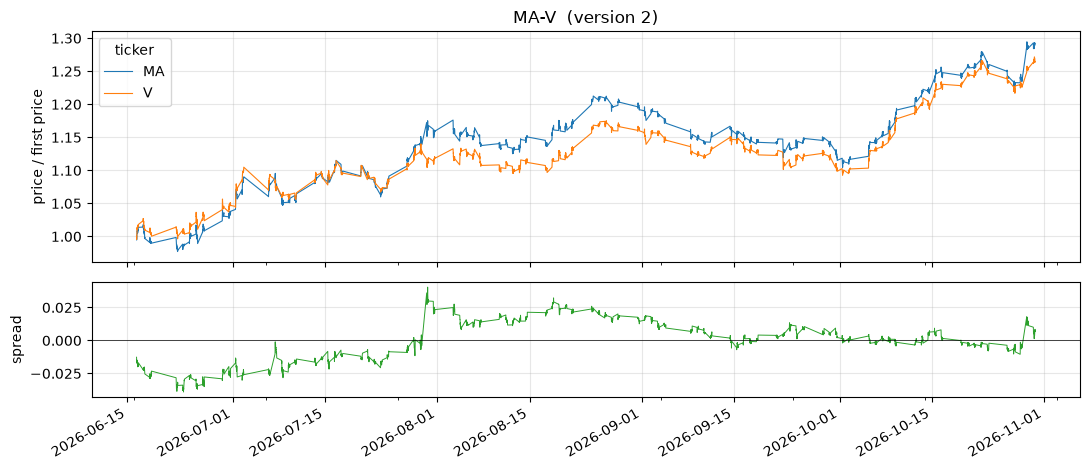

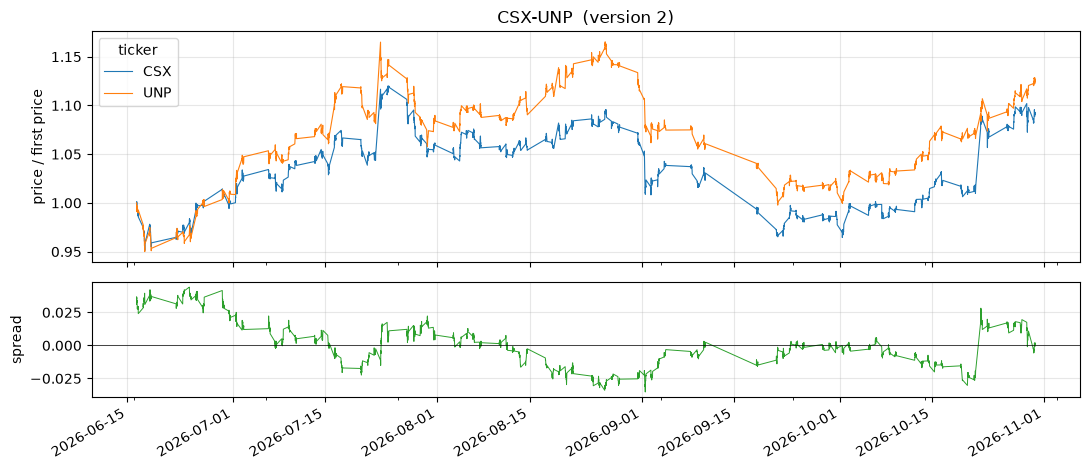

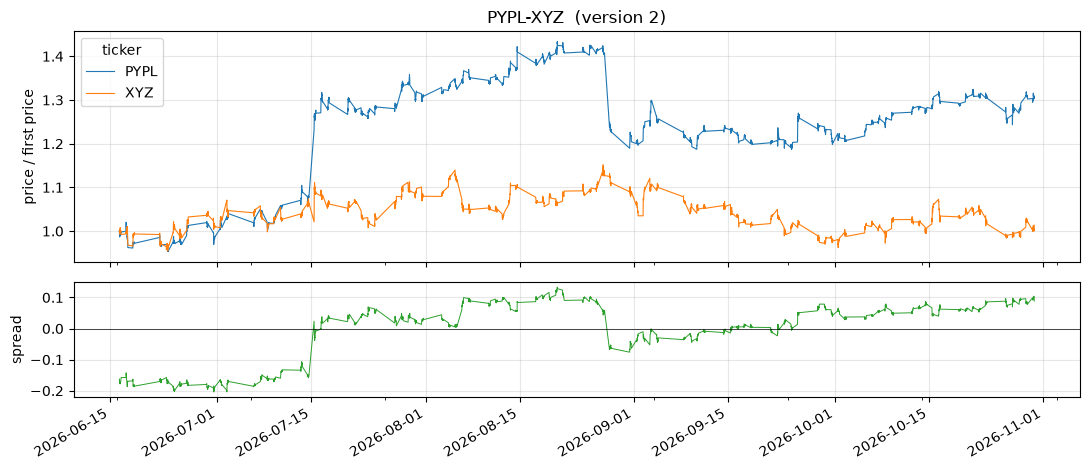

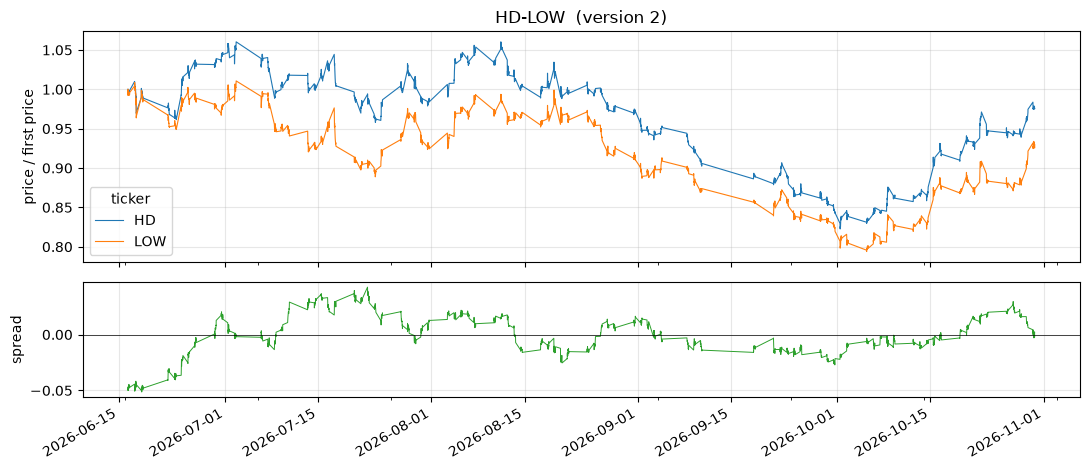

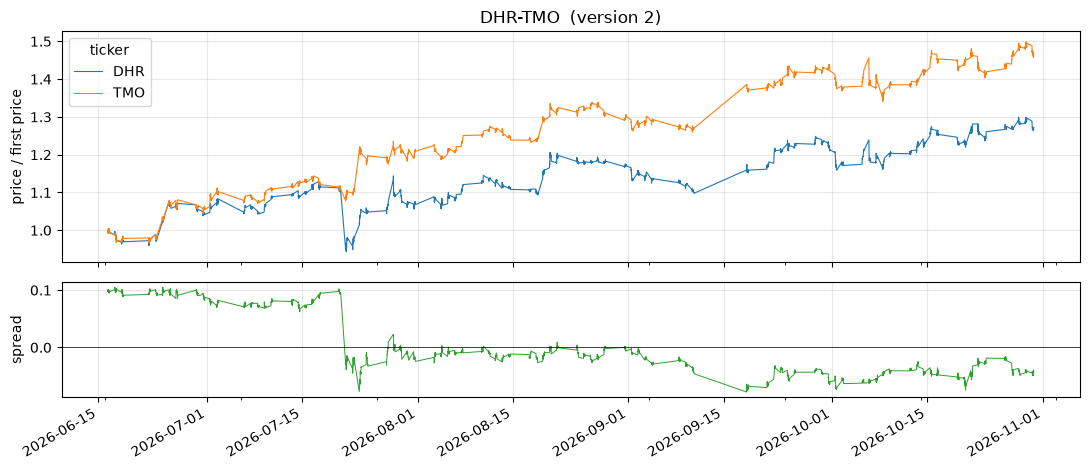

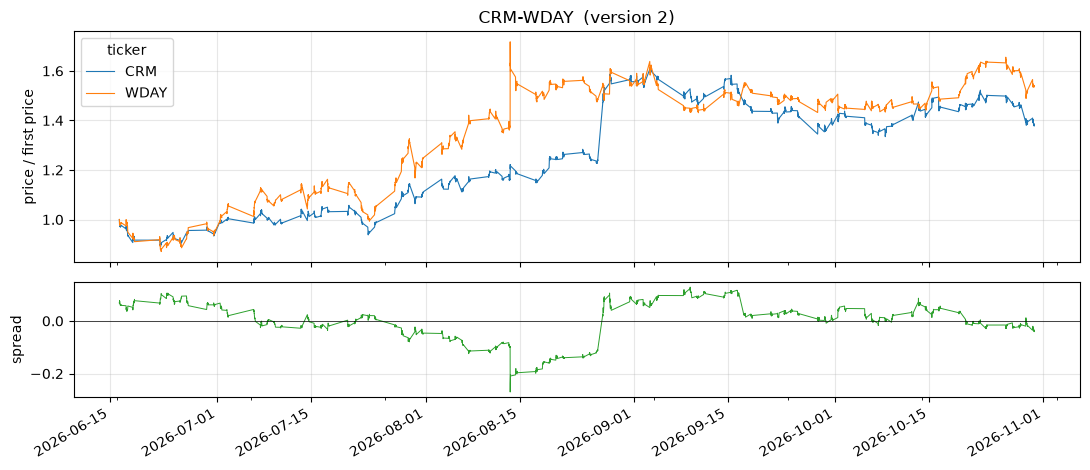

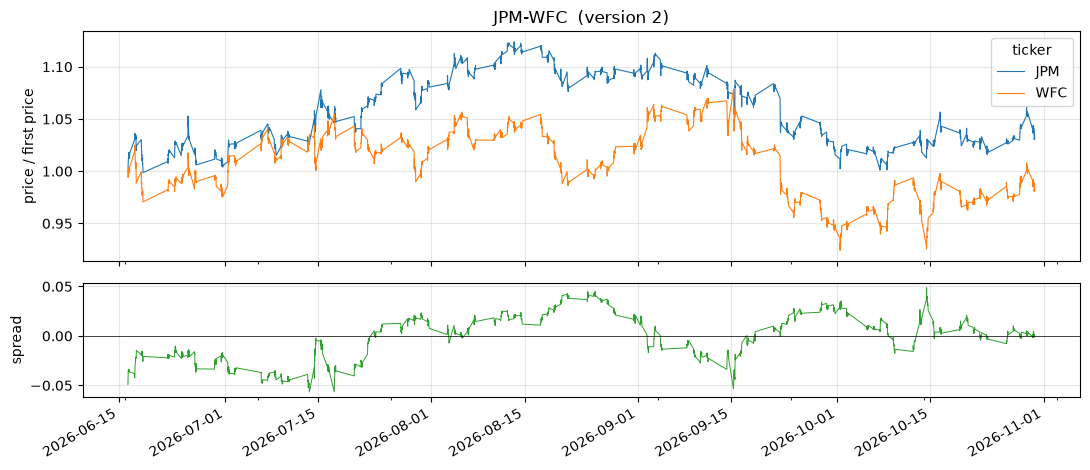

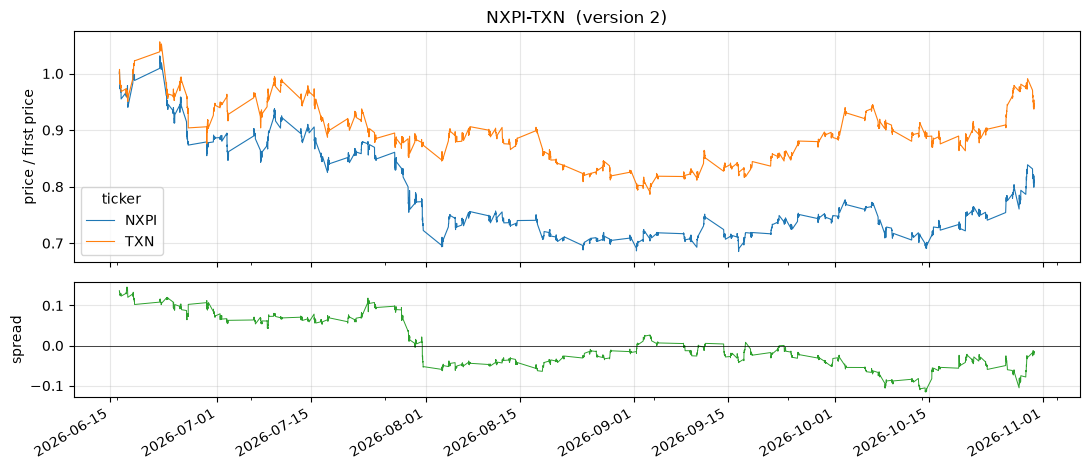

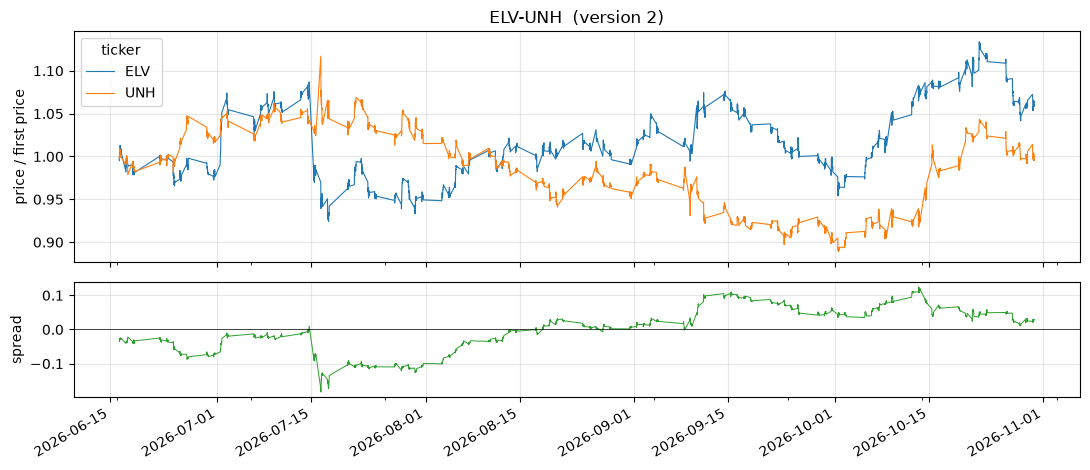

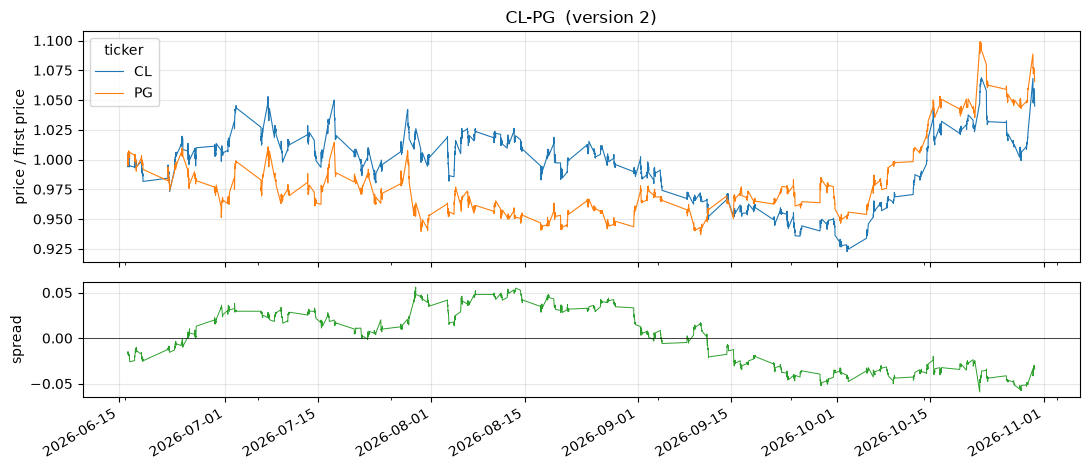

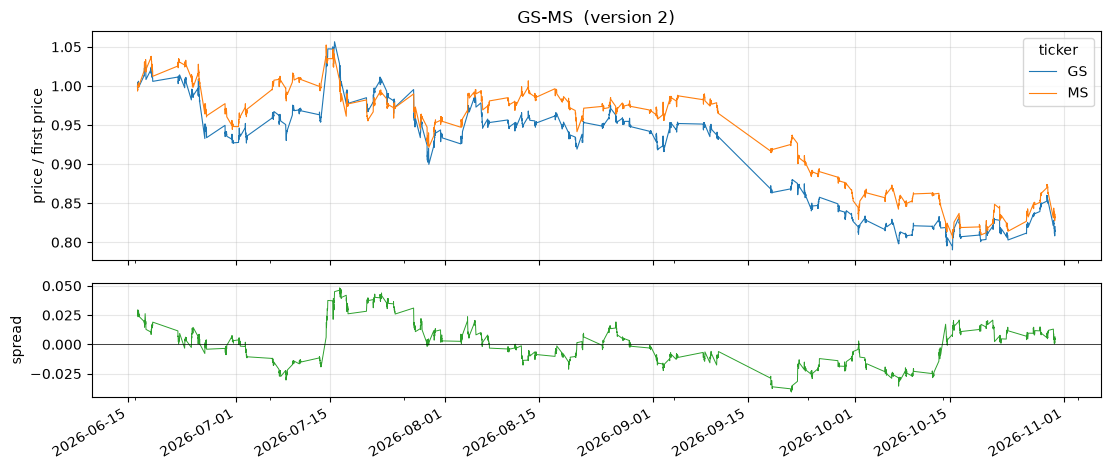

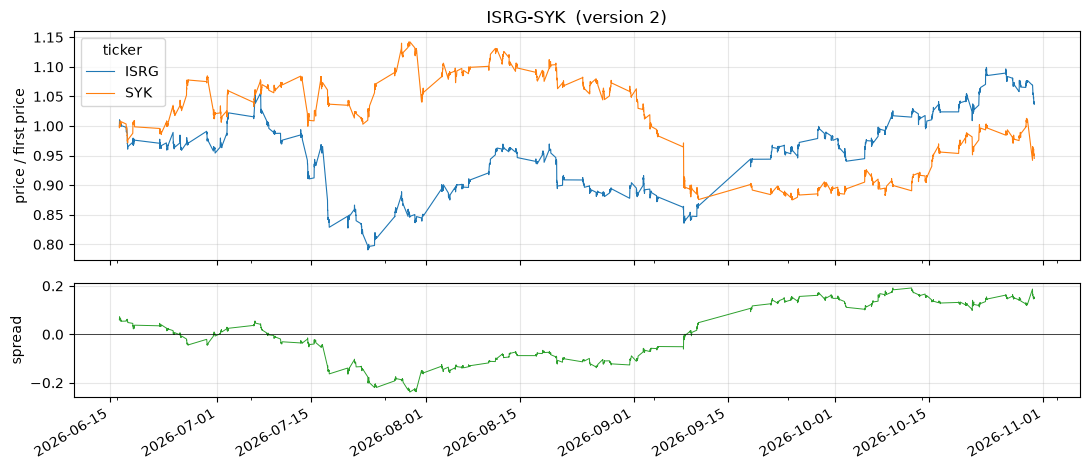

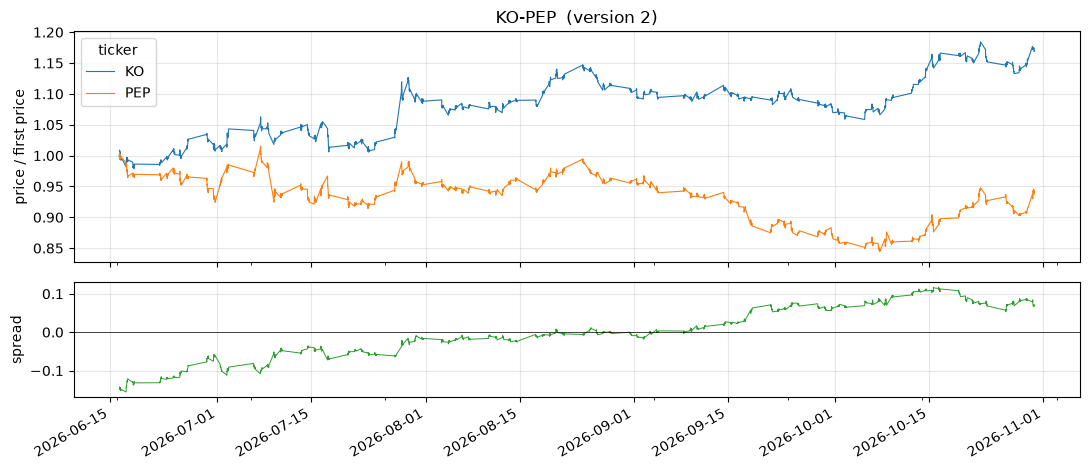

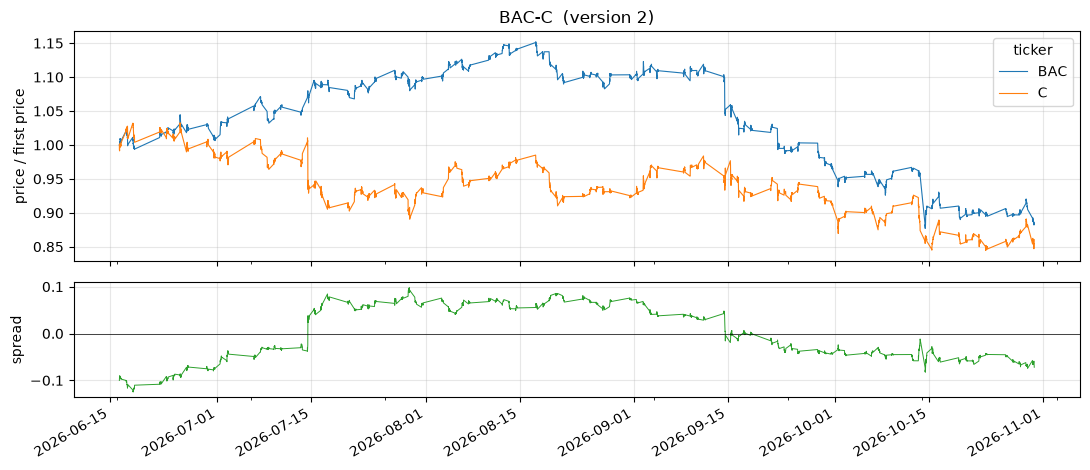

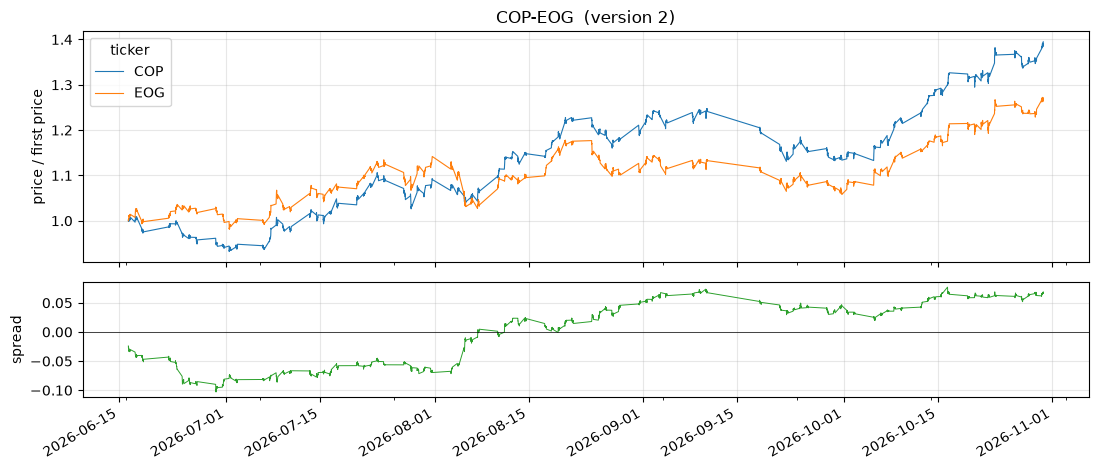

In [10]:
for p, long in clean.items():
    wide = resample_bars(long, 15).pivot(index="ts", columns="ticker", values="close")
    a, b = pairs.loc[pairs["pair"] == p, ["A", "B"]].iloc[0]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    (wide / wide.iloc[0]).rename(columns=lambda c: c.split()[0]).plot(ax=ax1, lw=0.8)
    ax1.set_title(f"{p}  ({pairs.loc[pairs['pair'] == p, 'origin'].iloc[0]})"); ax1.set_ylabel("price / first price"); ax1.grid(alpha=0.3)
    spread = np.log(wide[a] / wide[b]); (spread - spread.mean()).plot(ax=ax2, lw=0.7, color="C2")
    ax2.axhline(0, color="k", lw=0.5); ax2.set_ylabel("spread"); ax2.set_xlabel(""); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 9. Results (text for the report)

The next cell generates the text from the results of the notebook: if it is rerun with other data, the numbers update by themselves. It reports what was checked and what was done to the data of each pair.

In [11]:
from IPython.display import Markdown, display

n_days_all = len(day_bars)
bad_split = len(suspect_px)
big_gaps = suspect_gap[["ticker", "date", "gap"]]
q = quality.copy()
worst = pd.concat([q[["stock_A", "filled_%_A"]].set_axis(["stock", "filled"], axis=1), q[["stock_B", "filled_%_B"]].set_axis(["stock", "filled"], axis=1)]).sort_values("filled", ascending=False).head(5)
lost = q[q["initial_minutes_dropped"] > 0]["initial_minutes_dropped"].sort_values(ascending=False)
lines = [
    "### What we did",
    f"We cleaned the 1-minute data of the {len(tickers)} stocks of the {len(pairs)} version 2 pairs (same method as version 1): regular session 09:30-15:59 (390 bars per day), days in common for each pair, minutes without trades filled with the last price **of the same day** (never future prices, never prices of the day before), initial minutes without a price removed for both stocks. For each pair the frequencies {', '.join(str(m) for m in FREQUENCIES)} minutes are saved in `data/processed/pairs_intraday_v2/`.",
    "",
    "### Why",
    "Intraday prices are the material of the signal and of the simulation: they must have the same times for the two stocks and no future information (lookahead bias). The spread of a pair does not exist on a day on which one of the two stocks is missing, and a price copied across the night would be false.",
    "",
    "### Results",
    f"- **Period**: {raw['date'].min().date()} - {raw['date'].max().date()}, {n_days_all} trading days with at least one stock; half days: {len(half_days)}.",
    f"- **Splits**: {len(suspect_gap)} overnight gaps beyond {SPLIT_GAP:.0%}" + (" (" + ", ".join(f"{r.ticker.split()[0]} {r.date.date()} {r.gap:+.1%}" for r in big_gaps.itertuples()) + ")" if len(big_gaps) else "") + f"; {bad_split} cases of intraday close beyond {CLOSE_VS_DAILY_TOL:.0%} from the adjusted daily. " + ("No split in the stocks." if bad_split == 0 else "To be checked by hand before using the prices."),
    f"- **Days per pair**: from {int(q['days_kept'].min())} to {int(q['days_kept'].max())}; pairs with discarded days: " + (", ".join(f"{p} ({int(r)})" for p, r in q["days_dropped"][q["days_dropped"] > 0].items()) or "none") + ".",
    "- **Initial minutes removed** (whole period): " + (", ".join(f"{p} {int(v)}" for p, v in lost.items()) or "none") + ".",
    "- **Filled 1-minute bars**, most affected stocks: " + ", ".join(f"{r.stock} {r.filled:.0f}%" for r in worst.itertuples()) + ".",
    f"- **Jumps above {JUMP_1MIN:.0%} in one minute after cleaning**: {int(q[['jumps_1min_A', 'jumps_1min_B']].sum().sum())}.",
    "",
    "### What it means",
    "- Pairs with a stock that trades little have many filled minutes: there the 1-minute spread can move only because one leg is still. This is decision B of the plan (how to treat filled bars in the signal), to be taken before Step 4.",
    "- Pairs with fewer days have less data for training and test.",
    "- The train/test split and the base frequency are still to be decided (decisions A and 1 of the plan).",
]
display(Markdown("\n".join(lines)))

### What we did
We cleaned the 1-minute data of the 30 stocks of the 15 version 2 pairs (same method as version 1): regular session 09:30-15:59 (390 bars per day), days in common for each pair, minutes without trades filled with the last price **of the same day** (never future prices, never prices of the day before), initial minutes without a price removed for both stocks. For each pair the frequencies 1, 5, 15, 60 minutes are saved in `data/processed/pairs_intraday_v2/`.

### Why
Intraday prices are the material of the signal and of the simulation: they must have the same times for the two stocks and no future information (lookahead bias). The spread of a pair does not exist on a day on which one of the two stocks is missing, and a price copied across the night would be false.

### Results
- **Period**: 2026-06-16 - 2026-10-30, 96 trading days with at least one stock; half days: 0.
- **Splits**: 2 overnight gaps beyond 15% (DHR 2026-07-21 -16.5%, PYPL 2026-07-15 +15.8%); 0 cases of intraday close beyond 5% from the adjusted daily. No split in the stocks.
- **Days per pair**: from 91 to 96; pairs with discarded days: CSX-UNP (5), HD-LOW (5), DHR-TMO (5), GS-MS (5), ISRG-SYK (5), COP-EOG (5).
- **Initial minutes removed** (whole period): BAC-C 124, JPM-WFC 109, PYPL-XYZ 74, GS-MS 59, CL-PG 56, ISRG-SYK 35, HD-LOW 24, DHR-TMO 11, KO-PEP 4, CRM-WDAY 3, ELV-UNH 1.
- **Filled 1-minute bars**, most affected stocks: UNP 41%, ELV 36%, LOW 32%, DHR 25%, EOG 24%.
- **Jumps above 5% in one minute after cleaning**: 3.

### What it means
- Pairs with a stock that trades little have many filled minutes: there the 1-minute spread can move only because one leg is still. This is decision B of the plan (how to treat filled bars in the signal), to be taken before Step 4.
- Pairs with fewer days have less data for training and test.
- The train/test split and the base frequency are still to be decided (decisions A and 1 of the plan).

## 10. Saving and summary

One Parquet file is saved for each pair and frequency in `data/processed/pairs_intraday_v2/` (folder ignored by git: whoever in the group needs it reruns the notebook), plus the quality table in CSV. The files are in long format (one stock per row), as agreed for the next steps; the `load_pair` function below returns them already in wide form (one column per stock), handy to compute the spread.

In [12]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
n_files = 0
for p, long in clean.items():
    for m in FREQUENCIES:
        df = resample_bars(long, m) if m != 1 else long
        con.register("t", df)
        con.execute(f"COPY t TO '{(OUT_DIR / f'{p}_{m}min.parquet').as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)")
        con.unregister("t")
        n_files += 1
quality.to_csv(OUT_DIR / "quality_summary.csv")
print(n_files, "files saved in", f"data/processed/{OUT_DIR.name}")

60 files saved in data/processed/pairs_intraday_v2


In [13]:
def load_pair(pair, minutes=1, field="close"):
    # Reads a clean file and returns it in wide form: one row per time, one column per stock.
    df = duckdb.sql(f"SELECT * FROM '{(OUT_DIR / f'{pair}_{minutes}min.parquet').as_posix()}'").df()
    return df.pivot(index="ts", columns="ticker", values=field)

load_pair("KO-PEP", 15).head()

ticker,KO UN Equity,PEP UW Equity
ts,,
2026-06-16 09:30:00,80.49,146.45
2026-06-16 09:45:00,80.31,146.02
2026-06-16 10:00:00,80.94,146.36
2026-06-16 10:15:00,81.20,147.20
2026-06-16 10:30:00,80.68,146.31


**What was done and what remains open**
- The intraday prices of the 30 stocks of the version 2 pairs are checked (splits, missing days, half days), aligned per pair and forward-filled only within the day, without using future prices.
- For each pair there are the 1-, 5-, 15- and 60-minute files and the quality table, in `data/processed/pairs_intraday_v2/` (version 1 stays in `data/processed/pairs_intraday/`).
- **Limits to be stated in the report:**
  1. the intraday volume is only a part of the total volume (in a different share per exchange): it must be used as a relative indicator, not an absolute one;
  2. the share of filled bars is high for the stocks that trade little (spread that changes less often than it seems);
  3. discarded days for the pairs with missing data: fewer days available for training and test;
  4. prices not adjusted for dividends: in a few months dividends are few and small, but it stays an approximation;
  5. about 3 months of data: a single kind of market.
- **Next step** (Step 4): spread and signal on these files. The split between training and test (decision 3) is still to be fixed.